# OT2 (Tips + Liquid) — Dataset Preview

> A small **YOLO-style object detection dataset** built from OT2 lab videos exported frame-by-frame.

**What’s inside (as found in this repo):**
- **RGB frames** (mostly 640×480) split into `train/`, `valid/`, `test/`
- **YOLO txt labels** per frame with normalized bboxes
- **2 classes**: `Tip` and `Liquid`

This notebook audits what’s available, summarizes stats, and visualizes multiple frames per sample sequence with bbox overlays.

In [ ]:
from __future__ import annotations

import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Make repo dataset loaders importable in notebooks.
sys.path.append(str(Path("..") / "src"))
from datasets.ot2 import OT2Dataset

ROOT = (
    Path("..")
    / "data"
    / "OT2-Computer-Vision"
    / "Model_YoloNAS_50 epoch_Tips_n_liquid"
    / "Dataset"
 )
assert ROOT.exists(), f"Dataset root not found: {ROOT}"

SPLITS = ["train", "valid", "test"]
ot2 = OT2Dataset(ROOT, splits=SPLITS)

print(f"Dataset root: {ROOT.resolve()}")
print("Subfolders:", ", ".join([p.name for p in ROOT.iterdir() if p.is_dir()]))

if len(ot2) > 0 and isinstance(ot2[0].get("class_names"), dict):
    class_names = ot2[0]["class_names"]
else:
    class_names = {0: "Tip", 1: "Liquid"}
print("Classes:", class_names)

Dataset root: /media/gregory/BigOne/vlm_datasets/OT2-Computer-Vision/Model_YoloNAS_50 epoch_Tips_n_liquid/Dataset
Subfolders: checkpoints, test, train, valid
Classes: {0: 'Tip', 1: 'Liquid'}


## Capability audit (what’s available?)

This dataset follows the classic YOLO layout:
- `split/images/*.jpg`
- `split/labels/*.txt` (one file per image)

Each label line is: `class x_center y_center width height` in **normalized** coordinates.

In [ ]:
split_summary = {s: {"images": 0, "labels": 0, "missing_label_for_images": 0} for s in SPLITS}
sizes_counter: Counter[tuple[int, int]] = Counter()

for sample in ot2:
    split = str(sample.get("split", ""))
    if split not in split_summary:
        continue
    split_summary[split]["images"] += 1

    label_path = sample.get("label_path")
    if isinstance(label_path, str) and Path(label_path).exists():
        split_summary[split]["labels"] += 1
    else:
        split_summary[split]["missing_label_for_images"] += 1

    img_path = sample.get("rgb_image")
    if isinstance(img_path, Path) and img_path.exists():
        with Image.open(img_path) as im:
            sizes_counter[im.size] += 1

print("Split summary:")
for split, s in split_summary.items():
    images = s["images"]
    labels = s["labels"]
    missing_lbl = s["missing_label_for_images"]
    print(f"- {split:5s} images={images:>3d} labels={labels:>3d} missing_lbl={missing_lbl}")

print("\nImage sizes (WxH) distribution:")
for (w, h), cnt in sizes_counter.most_common(10):
    print(f"- {w}x{h}: {cnt}")

Split summary:
- train images= 55 labels= 55 missing_lbl=0 missing_img=0
- valid images= 10 labels= 10 missing_lbl=0 missing_img=0
- test  images=  6 labels=  6 missing_lbl=0 missing_img=0

Image sizes (WxH) distribution:
- 640x480: 71


## Dataset statistics

We compute:
- instance counts per class
- instances per frame distribution
- bbox width/height distributions (normalized)

Instance counts by class:
- 0 (Tip): 563
- 1 (Liquid): 432


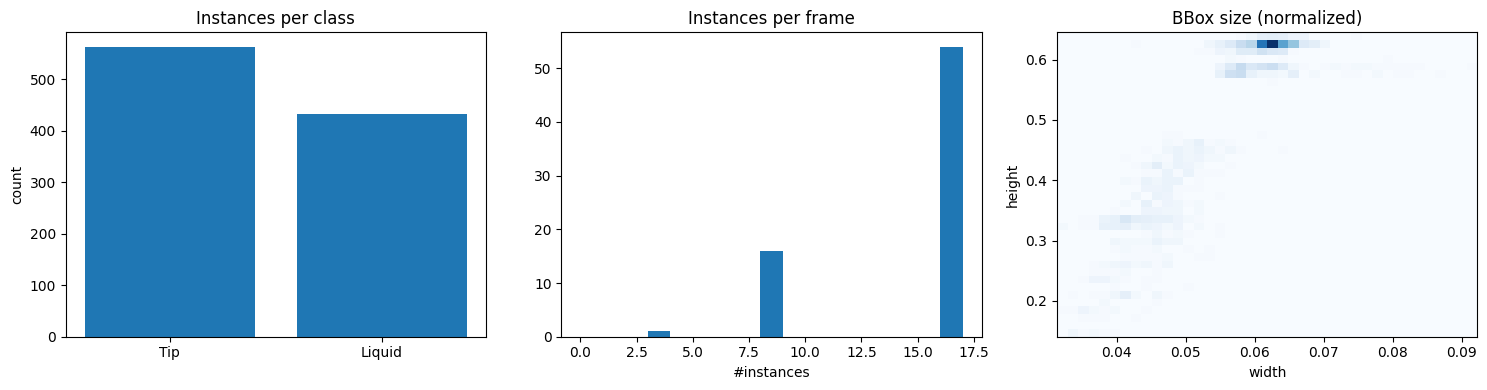

In [ ]:
cls_counts = Counter()
instances_per_frame = []
bbox_ws = []
bbox_hs = []

for sample in ot2:
    boxes = sample.get("yolo_boxes", [])
    if not isinstance(boxes, list):
        continue
    instances_per_frame.append(len(boxes))
    for b in boxes:
        if not isinstance(b, dict):
            continue
        cls = int(b.get("cls", -1))
        cls_counts[cls] += 1
        w = b.get("w")
        h = b.get("h")
        if isinstance(w, (int, float)):
            bbox_ws.append(float(w))
        if isinstance(h, (int, float)):
            bbox_hs.append(float(h))

print("Instance counts by class:")
for cls, cnt in sorted(cls_counts.items()):
    name = class_names.get(cls, "unknown")
    print(f"- {cls} ({name}): {cnt}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar([class_names.get(k, str(k)) for k in sorted(cls_counts)], [cls_counts[k] for k in sorted(cls_counts)])
axes[0].set_title("Instances per class")
axes[0].set_ylabel("count")

if instances_per_frame:
    axes[1].hist(instances_per_frame, bins=range(0, max(instances_per_frame) + 2))
axes[1].set_title("Instances per frame")
axes[1].set_xlabel("#instances")

if bbox_ws and bbox_hs:
    axes[2].hist2d(bbox_ws, bbox_hs, bins=40, cmap="Blues")
axes[2].set_title("BBox size (normalized)")
axes[2].set_xlabel("width")
axes[2].set_ylabel("height")

plt.tight_layout()
plt.show()

## “Video” sequences (frames grouped by filename)

The OT2 data is stored as independent frames. To present it like videos, we group frames by a simple rule:
- if a filename ends with `_<number>` (e.g. `tipsWater_4.jpg`), the part before the final underscore is treated as the **sequence id**.

This grouping is heuristic, but it works well for the frame-exported clips in this dataset.

Top sequences by frame count:
- train tipsWater            7 frames
- train DeckImage            6 frames
- train tipsWaterRed         6 frames
- valid tipsEmptyResdual     1 frames
- valid tipsWaterRed         1 frames
- test  tipsWaterRed         1 frames


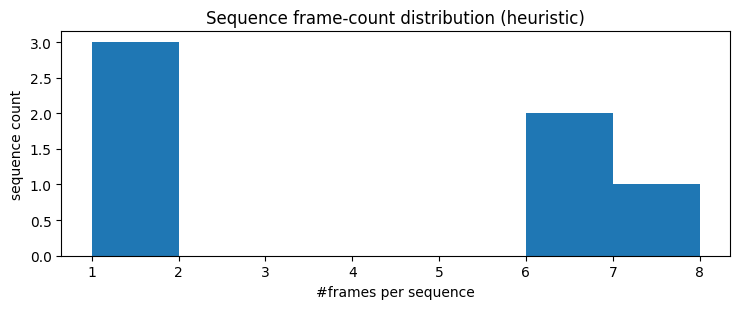

In [ ]:
def group_sequences(split: str) -> dict[str, list[dict]]:
    groups: dict[str, list[dict]] = defaultdict(list)
    for sample in ot2:
        if str(sample.get("split")) != split:
            continue
        sid = sample.get("sequence_id")
        idx = sample.get("frame_index")
        if isinstance(sid, str) and isinstance(idx, int):
            groups[sid].append(sample)
    for sid in list(groups.keys()):
        groups[sid] = sorted(groups[sid], key=lambda s: int(s.get("frame_index", 0)))
    return dict(groups)

seq_stats = []
seq_by_split = {}
for split in SPLITS:
    groups = group_sequences(split)
    seq_by_split[split] = groups
    for sid, frames in groups.items():
        seq_stats.append((split, sid, len(frames)))

seq_stats = sorted(seq_stats, key=lambda x: x[2], reverse=True)
print("Top sequences by frame count:")
for split, sid, n in seq_stats[:15]:
    print(f"- {split:5s} {sid:20s} {n} frames")

if seq_stats:
    plt.figure(figsize=(7.5, 3.2))
    plt.hist([n for _, _, n in seq_stats], bins=range(1, max([n for _, _, n in seq_stats]) + 2))
    plt.title("Sequence frame-count distribution (heuristic)")
    plt.xlabel("#frames per sequence")
    plt.ylabel("sequence count")
    plt.tight_layout()
    plt.show()

## Multi-frame visualization with bbox overlays

The helper below loads multiple frames from a chosen sequence and overlays YOLO bboxes for both classes.

Example sequence: split=train seq=tipsWater (7 frames)


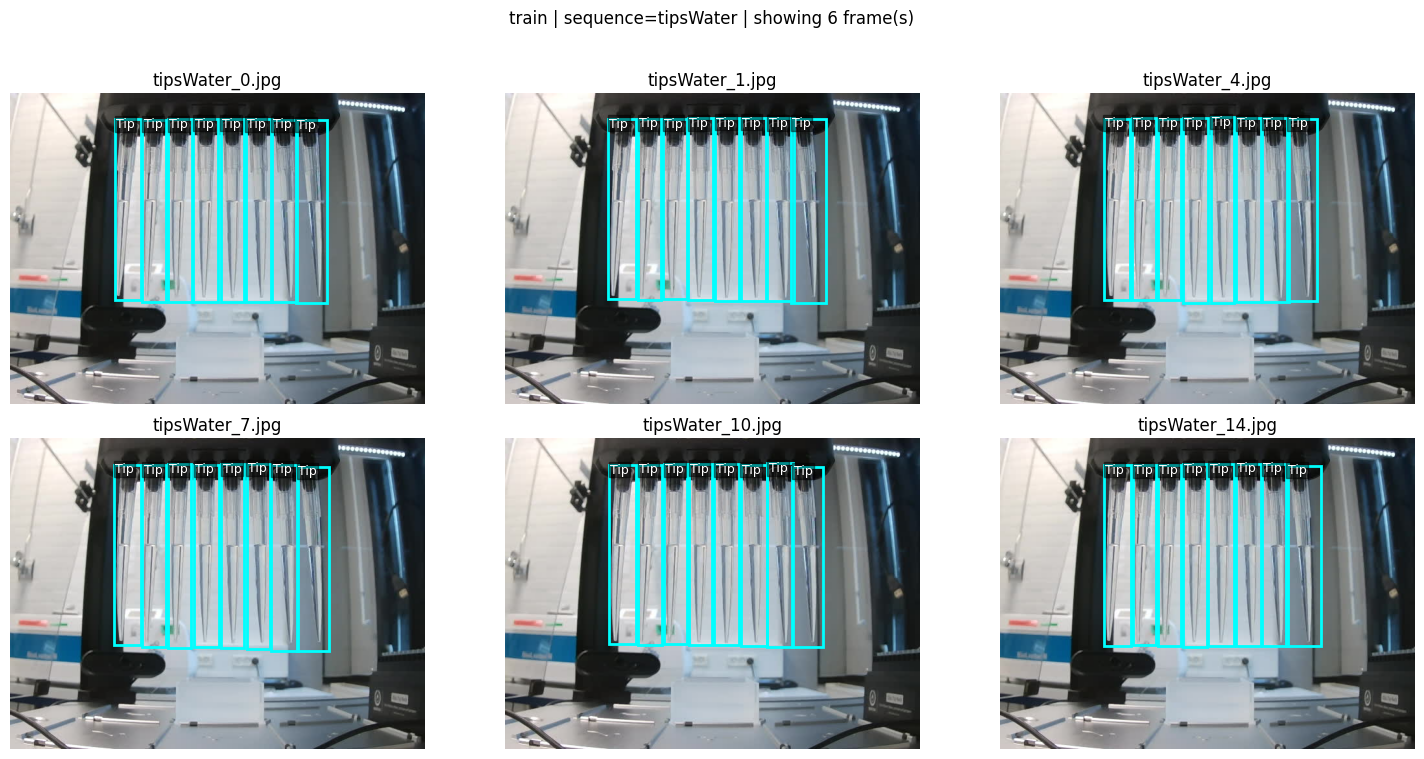

In [ ]:
def load_rgb(path: Path) -> np.ndarray:
    # Pillow gives consistent RGB arrays for jpg/png
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def yolo_to_xyxy(box: dict, w: int, h: int) -> tuple[float, float, float, float]:
    xc = float(box.get("xc", 0.0))
    yc = float(box.get("yc", 0.0))
    bw = float(box.get("w", 0.0))
    bh = float(box.get("h", 0.0))
    x1 = (xc - bw / 2.0) * w
    y1 = (yc - bh / 2.0) * h
    x2 = (xc + bw / 2.0) * w
    y2 = (yc + bh / 2.0) * h
    return x1, y1, x2, y2


def draw_boxes(ax, boxes: list[dict], w: int, h: int):
    # fixed colors for the known classes
    colors = {0: "cyan", 1: "magenta"}
    for b in boxes:
        if not isinstance(b, dict):
            continue
        cls = int(b.get("cls", -1))
        x1, y1, x2, y2 = yolo_to_xyxy(b, w, h)
        rect = plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2, color=colors.get(cls, "lime")
        )
        ax.add_patch(rect)
        ax.text(
            x1 + 2,
            y1 + 12,
            class_names.get(cls, str(cls)),
            color="white",
            fontsize=9,
            bbox=dict(facecolor="black", alpha=0.45, pad=1),
        )


def show_sequence(split: str, sequence_id: str, n_frames: int = 6, cols: int = 3):
    groups = seq_by_split.get(split) or group_sequences(split)
    frames = groups.get(sequence_id)
    if not frames:
        raise ValueError(
            f"No sequence {sequence_id!r} found in split={split!r}. Available: {list(groups)[:10]} ..."
        )

    frames = frames[:n_frames]
    rows = int(np.ceil(len(frames) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.7 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, sample in zip(axes, frames):
        img_path = sample.get("rgb_image")
        if not isinstance(img_path, Path):
            ax.axis("off")
            continue
        rgb = load_rgb(img_path)
        h, w = rgb.shape[:2]
        boxes = sample.get("yolo_boxes", [])
        boxes = boxes if isinstance(boxes, list) else []

        ax.imshow(rgb)
        draw_boxes(ax, boxes, w=w, h=h)
        ax.set_title(img_path.name)
        ax.axis("off")

    for ax in axes[len(frames) :]:
        ax.axis("off")

    fig.suptitle(f"{split} | sequence={sequence_id} | showing {len(frames)} frame(s)", y=1.02)
    plt.tight_layout()
    plt.show()


# Pick a multi-frame sequence if available; otherwise fall back to any single image
if seq_stats:
    best_split, best_seq, best_n = seq_stats[0]
    print(f"Example sequence: split={best_split} seq={best_seq} ({best_n} frames)")
    show_sequence(best_split, best_seq, n_frames=min(6, best_n), cols=3)
else:
    # fallback: show first few train frames
    fallback = [s for s in ot2 if str(s.get("split")) == "train"][:6]
    print("No sequences detected; showing first images:", [Path(s["path"]).name for s in fallback])
    seq_by_split.setdefault("train", {})["__fallback__"] = fallback
    show_sequence("train", "__fallback__", n_frames=len(fallback), cols=3)

## Random frame panel (across splits)

Sometimes it’s useful to quickly sample diverse frames (not necessarily from the same sequence).

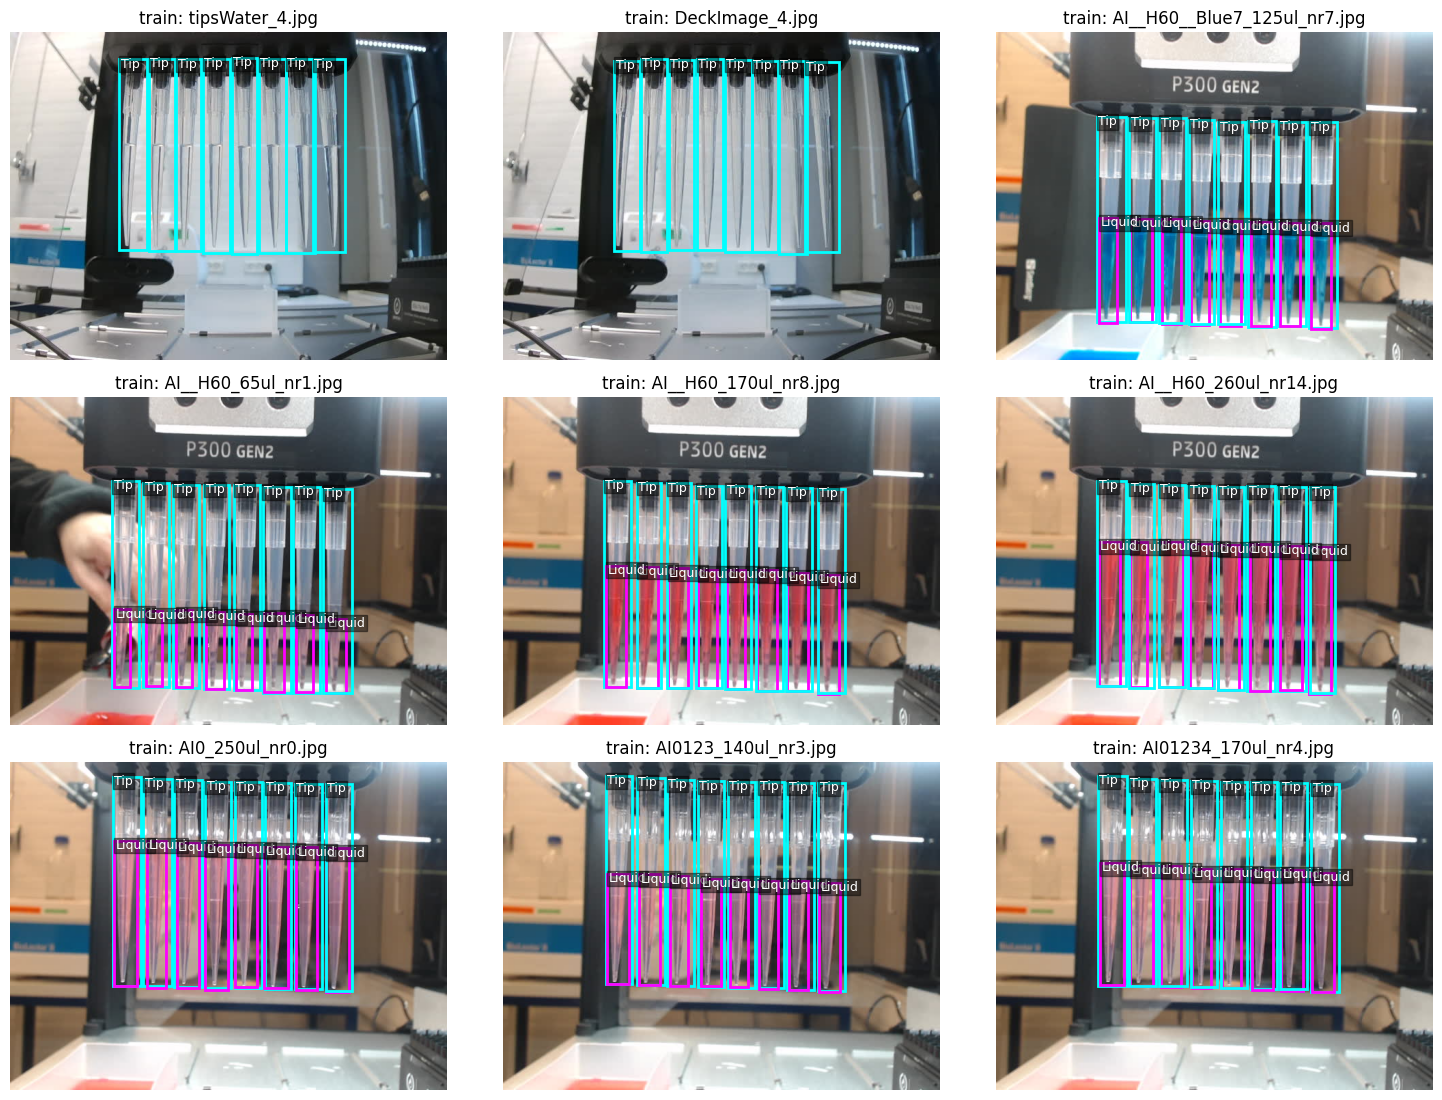

In [ ]:
rng = np.random.default_rng(0)

def show_random_frames(n: int = 9, cols: int = 3):
    all_samples = list(ot2)
    if not all_samples:
        print("No images found")
        return

    idxs = rng.choice(len(all_samples), size=min(n, len(all_samples)), replace=False)
    chosen = [all_samples[int(i)] for i in idxs]

    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.7 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, sample in zip(axes, chosen):
        img_path = sample.get("rgb_image")
        if not isinstance(img_path, Path):
            ax.axis("off")
            continue
        rgb = load_rgb(img_path)
        h, w = rgb.shape[:2]
        boxes = sample.get("yolo_boxes", [])
        boxes = boxes if isinstance(boxes, list) else []

        ax.imshow(rgb)
        draw_boxes(ax, boxes, w=w, h=h)
        split = str(sample.get("split", ""))
        ax.set_title(f"{split}: {img_path.name}")
        ax.axis("off")

    for ax in axes[len(chosen) :]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_random_frames(n=9, cols=3)

## Takeaways

- The OT2 dataset in this repo is a **YOLO detection dataset** with two semantic classes: **Tip** and **Liquid**.
- Each frame includes **multi-instance bboxes**, enabling detection and counting tasks.
- Some clips are represented as **frame sequences** (e.g. `tipsWater_*`, `tipsWaterRed_*`, `DeckImage_*`), which makes it easy to treat them as short videos for qualitative evaluation.

If you want, I can extend this notebook to compute per-sequence aggregates (e.g., liquid bbox height trends across frames) — but I’ve kept the UX minimal and focused on dataset capabilities.